# Final project: Lena Einramhof

In [1]:
import os
import random
import glob
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np
import torch.nn.functional
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from sklearn.metrics import r2_score
import torch.nn as nn
import torch.nn.functional as F
import time
import gc

## Data processing

In [2]:
#specify paths for training, test and validation data 
DATA_ROOT = "../../../../../../mnt/data/lena/simulations"
TEST_ROOT = "../../../../../../mnt/data/lena/simulations_test"  
VAL_ROOT = "../../../../../../mnt/data/lena/simulations_validation"

In [3]:
#computing the avg mean and std density contrast across all the training data set
def compute_global_stats(root_dir):
    means, stds = [], []
    for sim in os.listdir(root_dir):  #go in every directory inside of rootdir
        sim_path = os.path.join(root_dir, sim) #create a path into that directory
        for f in os.listdir(sim_path): #go through all the files starting with "density_" 
            if f.startswith("density_"):
                x = np.load(os.path.join(sim_path, f), mmap_mode="r") #loading the density cube and calculating mean and std and appending
                means.append(x.mean())
                stds.append(x.std())

    means = np.array(means)
    stds = np.array(stds)

    global_mean = means.mean()                        
    global_std = np.sqrt( np.mean(stds ** 2)  + np.var(means))      #total variance  

    return global_mean, global_std


DENSITY_MEAN, DENSITY_STD = compute_global_stats(DATA_ROOT)
print(f"Global mean: {DENSITY_MEAN:.20f}")
print(f"Global std: {DENSITY_STD:.20f}")

Global mean: -0.00000000038029004945
Global std: 4.38411664962768554688


In [4]:
class ShapeTrainDataset(Dataset):
    """
    Loading all trainings data file from root directory (density field, labels). Random cropping to a cube of size cube_size for each simulation.
    Random data augmentation via flipping and 90 degree rotation.
    Normalization based on the full trainings data mean and variance (z-score).

    
    """

    def __init__(self, root_dir, cube_size=96, augment=True,
                 cache_mode="mmap"):
        self.root_dir = root_dir
        self.cube_size = cube_size
        self.augment = augment
        self.cache_mode = cache_mode

        self.sims = [
            os.path.join(root_dir, sim)
            for sim in os.listdir(root_dir)
            if os.path.isdir(os.path.join(root_dir, sim))
        ] #contains all the simulations from the root training folder

    def __len__(self):
        return len(self.sims)

    def _find_file(self, sim_path, prefix):
        for f in os.listdir(sim_path):
            if f.startswith(prefix):
                return os.path.join(sim_path, f)
        raise FileNotFoundError(f"No file starting with '{prefix}' in {sim_path}")

    def load_sim(self, sim_path):
        density_path = self._find_file(sim_path, "density_")
        label_path_ba = self._find_file(sim_path, "label_ba_")
        label_path_ca = self._find_file(sim_path, "label_ca_")


        if self.cache_mode == "mmap": #memory efficient for large objects like simulation cubes
            density = np.load(density_path, mmap_mode="r")
            labels_ba = np.load(label_path_ba, mmap_mode="r")
            labels_ca = np.load(label_path_ca, mmap_mode="r")

        else: 
            density = np.load(density_path)
            labels_ba = np.load(label_path_ba)
            labels_ca = np.load(label_path_ca)
        
        labels = np.stack([labels_ba, labels_ca], axis=0)

        return density, labels

    def normalize(self, x): # normalization (z-score) via the calulated mean density and the variance between the simulation training set
        return (x - DENSITY_MEAN) / (DENSITY_STD + 1e-8)
    
    def random_crop(self, x, y):
        c = self.cube_size
        X, Y, Z = x.shape
        #selecting random window starting point 
        x0 = random.randint(0, X - 1)
        y0 = random.randint(0, Y - 1)
        z0 = random.randint(0, Z - 1)

        #wrapping if the crop window would go across the boundary
        idx_x = np.arange(x0, x0 + c) % X
        idx_y = np.arange(y0, y0 + c) % Y
        idx_z = np.arange(z0, z0 + c) % Z

        x_crop = x[np.ix_(idx_x, idx_y, idx_z)]

        idx_c = np.arange(y.shape[0])
        y_crop =  y[np.ix_(idx_c, idx_x, idx_y, idx_z)]

        return x_crop, y_crop

    #randoming flipping  along any of the three axis both density and labels
    def random_flip(self, x, y):
        for ax in [0, 1, 2]:
            if random.random() < 0.5:
                x = np.flip(x, axis=ax)
                y = np.flip(y, axis=ax+1)
        return x, y

    #randomly rotating by multiples of 90 degrees at a random axis both density and labels
    def random_rot90(self, x, y):
        k = random.randint(0, 3)
        axes = random.choice([(0, 1), (0, 2), (1, 2)])
        x = np.rot90(x, k, axes)
        y = np.rot90(y, k, tuple(a+1 for a in axes))
        return x, y

    def __getitem__(self, idx):
        sim = self.sims[idx]
        x, y = self.load_sim(sim)

        x_crop, y_crop = self.random_crop(x, y)
        x_crop = self.normalize(x_crop)

        if self .augment:
            x_crop, y_crop = self.random_flip(x_crop, y_crop)
            x_crop, y_crop = self.random_rot90(x_crop, y_crop)

        #change all labels that are originally nan (background) to 0.0 & save mask for all particles originally in halos
        mask_crop = ~np.isnan(y_crop[0])
        y_clean = np.nan_to_num(y_crop, nan=0.0)

        x_t = torch.from_numpy(x_crop.copy()).float().unsqueeze(0)  
        y_t = torch.from_numpy(y_clean.copy()).float() 
        y_t = torch.nan_to_num(y_t, nan=0.0)

        mask_t = torch.from_numpy(mask_crop.copy()).float().unsqueeze(0)

        return x_t, y_t, mask_t 


class ShapeTestDataset(Dataset):
    """
    Similar to the CosmologyTrainingDataset but for the test/validation case no random cropping or data augmentation.
    normalization based on the trainings data global mean and variance.
    
    """

    def __init__(self, root_dir):
        self.root_dir = root_dir
        self.sims = [
            os.path.join(root_dir, sim)
            for sim in os.listdir(root_dir)
            if os.path.isdir(os.path.join(root_dir, sim))
        ]

    def __len__(self):
        return len(self.sims)

    def load_sim(self, sim_path):
        density_file = [f for f in os.listdir(sim_path) if f.startswith("density_")][0]
        label_file_ba = [f for f in os.listdir(sim_path) if f.startswith("label_ba_")][0]
        label_file_ca = [f for f in os.listdir(sim_path) if f.startswith("label_ca_")][0]

        density = np.load(os.path.join(sim_path, density_file))
        labels_ba = np.load(os.path.join(sim_path, label_file_ba))
        labels_ca = np.load(os.path.join(sim_path, label_file_ca))

        labels = np.stack([labels_ba, labels_ca], axis=0)

        return density, labels

    def normalize(self, x):
        return  (x - DENSITY_MEAN) / (DENSITY_STD + 1e-8)

    def __getitem__(self, idx):
        sim = self.sims[idx]
        x, y = self.load_sim(sim)
        x = self.normalize(x)

        #change all labels that are originally nan (background) to 0.0 & save mask for all particles originally in halos
        mask = ~np.isnan(y[0])
        y_clean = np.nan_to_num(y, nan=0.0)

        x_t = torch.from_numpy(x.copy()).float().unsqueeze(0)
        y_t = torch.from_numpy(y_clean.copy()).float()
        y_t = torch.nan_to_num(y_t, nan=0.0)
        mask_t = torch.from_numpy(mask.copy()).float().unsqueeze(0)
        return x_t, y_t, mask_t, sim

In [5]:
OUT_CH = 2 #number of channels for the network to return: b/a and c/a
CUBE_SIZE = 80 #the subvolume used for training due to limited gpu ram
BATCH_SIZE = 8 #batchsize for training
NUM_WORKERS = 8

train_ds = ShapeTrainDataset(DATA_ROOT, cube_size=CUBE_SIZE, augment=True, cache_mode="mmap")

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    shuffle=True,
    pin_memory=True,
    persistent_workers=True,
)

val_ds = ShapeTestDataset(VAL_ROOT)
val_loader = DataLoader(val_ds, batch_size=1, num_workers=1, shuffle=False)

test_ds = ShapeTestDataset(TEST_ROOT)
test_loader = DataLoader(test_ds, batch_size=1, num_workers=1, shuffle=False)

print(f"Train sims: {len(train_ds.sims)}")
print(f"Test volumes: {len(test_ds)}") 
print(f"Validation volumes: {len(val_ds)}")

Train sims: 90
Test volumes: 10
Validation volumes: 10


## Model & loss

In [6]:
# define a classical convolution operator
# with in channels and out channels
#this operator keeps the spatial dimension the same 
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, padding_mode="circular"), #3d conv operation with a 3x3x3 filter kernel and padding 1, the padding is applied circular concistent with simulations
            nn.LeakyReLU(0.05, inplace=True), #activation function leakyrelu for nonlinearity
            nn.Conv3d(out_ch, out_ch, 3, padding=1, padding_mode="circular"),  #3d conv operation with a 3x3x3 filter kernel and padding 1, the padding is applied circular concistent with simulations
            nn.LeakyReLU(0.05, inplace=True),  #activation function leakyrelu for nonlinearity
        )

    def forward(self, x):
        return self.net(x)


class VNetShape(nn.Module):
    def __init__(self, in_ch=1, out_ch=2, base=32, dropout=0): #turn off drop out! 
        super().__init__()

        #encoder
        self.enc1 = ConvBlock(in_ch, base) #start with normal convolutional operation on the full volume of the sim -> increasing filter depth
        self.drop1 = nn.Dropout3d(dropout) #apply dropout to avoid overfitting
        self.pool1 = nn.MaxPool3d(2) #max pooling to reduce the spatial size of the cube for the next layer (by half)

        self.enc2 = ConvBlock(base, base * 2) #repeating decoding block now further increasing the filter depth
        self.drop2 = nn.Dropout3d(dropout)
        self.pool2 = nn.MaxPool3d(2)

        self.enc3 = ConvBlock(base * 2, base * 4) #again
        self.drop3 = nn.Dropout3d(dropout)
        self.pool3 = nn.MaxPool3d(2)

        self.bottleneck = ConvBlock(base * 4, base * 8) # maximum compression (bottleneck)
 
        #------- decoder -------
        self.up3 = nn.ConvTranspose3d(base * 8, base * 4, 2, stride=2) # conv transpose with stride to essentially increasing (doubling) the spatial dimensions adn using a filter of size 2x2x2
        self.dec3 = ConvBlock(base * 8, base * 4) #classic convolution operation now decreasing the filter depth again

        self.up2 = nn.ConvTranspose3d(base * 4, base * 2, 2, stride=2) #again repeat doubling spatial dimension halfing the channel depth
        self.dec2 = ConvBlock(base * 4, base * 2)

        self.up1 = nn.ConvTranspose3d(base * 2, base, 2, stride=2)
        self.dec1 = ConvBlock(base * 2, base)

        self.out = nn.Conv3d(base, out_ch, 1) # final output must be a value for each of the class numbers, by using a 1x1x1 kernel to make prediction for each voxel

    def forward(self, x):
        x1 = self.enc1(x) #encoding 1
        x2 = self.enc2(self.pool1(self.drop1(x1))) #pooling and encoding
        x3 = self.enc3(self.pool2(self.drop2(x2))) # pooling and encoding
        x4 = self.bottleneck(self.pool3(self.drop3(x3))) #pooling and bottleneck

        y3 = self.dec3(torch.cat([self.up3(x4), x3], dim=1)) # concatenate (skip connection between the different unet depth layers) then decoding
        # up3(x4) has base*4 channels, x3 (skip) has base*4 channels concatenated -> base*8 channels in, base*4 channels out (per ConvBlock def)
        y2 = self.dec2(torch.cat([self.up2(y3), x2], dim=1)) #skip connectors and decodin
        y1 = self.dec1(torch.cat([self.up1(y2), x1], dim=1)) #skip connectors and decodin

        return self.out(y1) #output in (0,1)
        #return torch.nn.functional.hardsigmoid(self.out(y1))
        #return torch.sigmoid(self.out(y1)) #output in (0,1)
    

#mse loss 
def mse_loss_per_channel(pred, target):
    squared_err = (pred-target)**2  
    mse_ba  = squared_err[:,0].sum() / CUBE_SIZE**3
    mse_ca  = squared_err[:,1].sum() / CUBE_SIZE**3
    return mse_ba, mse_ca


## Early Stop

In [7]:
#early stopper class which is triggered when "patience" consecutive epochs pass 
#without the evaluation loss improving on the previous best by more than min_delta
#then the should stop is set and it will trigger the stopping of training
class EarlyStopper:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.should_stop = False

    def step(self, val_loss):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            return True   
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
            return False 

## Training

In [8]:
torch.backends.cudnn.benchmark = True
device = "cuda" if torch.cuda.is_available() else "cpu" #selecting cuda if available otherwise cpu

MAX_NUM_EPOCHS = 1000 #max number of epochs
LR = 1e-4 #learning rate
model = VNetShape(out_ch=OUT_CH).to(device, memory_format=torch.channels_last_3d) #model initialization

start_epoch = 0
early_stopper = EarlyStopper(patience=40, min_delta=1e-4) #initialize early stop
opt = torch.optim.Adam(model.parameters(), lr=LR) #set optimizer and learning rate
scaler = torch.amp.GradScaler("cuda")# gradient scaler for mixed-precision trainin


In [ ]:
loss_history = []
val_loss_history = []

for epoch in range(MAX_NUM_EPOCHS): #loop over all epochs
    model.train()
    running_loss = 0.0
    t0 = time.time()

    #training
    for x, y, mask in train_loader: #iterate over the batches loaded from the training set
        x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last_3d) #move input batch to the GPU
        y = y.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)

        opt.zero_grad(set_to_none=True)  #clear gradients 

        with torch.amp.autocast("cuda"):
            pred = model(x)  #forward pass through network prediction
            mse_ba, mse_ca = mse_loss_per_channel(pred, y) #calculate loss 
            loss = mse_ba + mse_ca 
            del mse_ba, mse_ca

        scaler.scale(loss).backward() #backwards compute gradients
        scaler.step(opt) #optimizer update
        scaler.update() #update loss scaling factor
        running_loss += loss.item() #add loss

        del x, y, mask, pred, loss #free up memory

    train_epoch_loss = running_loss / len(train_loader) #average loss
    loss_history.append(train_epoch_loss)

    #validation
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad(): #no gradiant calculation for validation
        for x, y, mask, _ in val_loader: #go through the 10 validation simulations (batchsize=1)
            x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last_3d) #send to gpu
            y = y.to(device, non_blocking=True)
            mask = mask.to(device, non_blocking=True)

            pred = model(x) #evaluate
            val_mse_ba, val_mse_ca = mse_loss_per_channel(pred, y) #loss
            val_loss = val_mse_ba + val_mse_ca 
            running_val_loss += val_loss.item()

            del x, y, mask, pred, val_loss #free up space

    val_epoch_loss = running_val_loss / len(val_loader)
    val_loss_history.append(val_epoch_loss)

    dt = time.time() - t0
    print(f"Epoch {epoch}:")
    print(f"Train_loss={train_epoch_loss:.4f},  val_loss={val_epoch_loss:.4f}  ({dt:.1f}s)")

    #check if model has improved in this epoch
    improved = early_stopper.step(val_epoch_loss)
    if improved: # save a copy of the best-performing model weights
        best_state = {
            "state_dict": {k: v.cpu().clone() for k, v in model.state_dict().items()},
            "loss_history": list(loss_history),         
            "val_loss_history": list(val_loss_history),  
            "epoch": epoch                              
        }

    if early_stopper.should_stop:
        print(f"Early stopping at epoch {epoch} (no improvement for {early_stopper.patience} epochs)")
        break



In [ ]:
#save the model
torch.save(best_state, "model_best_background_nosigmoid_dropout_loss.pt")

In [9]:
#load the model
device = "cuda" if torch.cuda.is_available() else "cpu"
model = VNetShape(out_ch=2) 

checkpoint = torch.load("model_best_background_nosigmoid_nodropout_loss.pt", map_location=device)
model.load_state_dict(checkpoint["state_dict"])

model.to(device)

VNetShape(
  (enc1): ConvBlock(
    (net): Sequential(
      (0): Conv3d(1, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (1): LeakyReLU(negative_slope=0.05, inplace=True)
      (2): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (3): LeakyReLU(negative_slope=0.05, inplace=True)
    )
  )
  (drop1): Dropout3d(p=0, inplace=False)
  (pool1): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): ConvBlock(
    (net): Sequential(
      (0): Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (1): LeakyReLU(negative_slope=0.05, inplace=True)
      (2): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (3): LeakyReLU(negative_slope=0.05, inplace=True)
    )
  )
  (drop2): Dropout3d(p=0, inplace=False)
  (pool2): MaxPool3d(kernel_size=2, stride=2, padding=

### Training curves

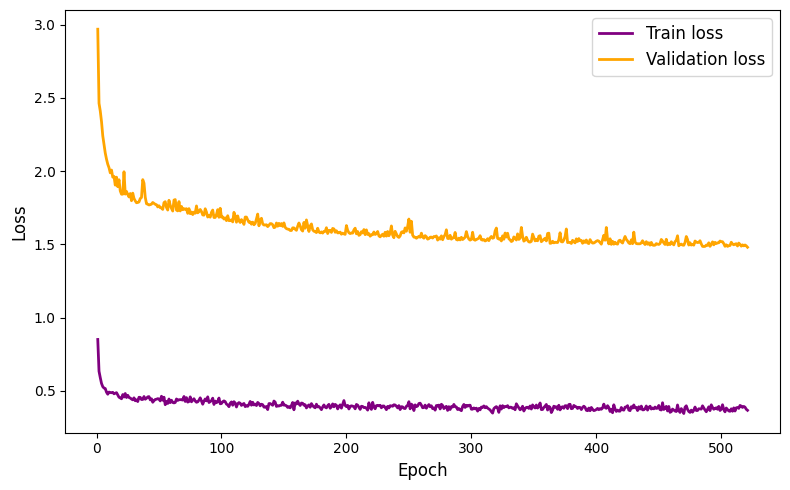

In [10]:
#plot the loss curves
loss_history = checkpoint["loss_history"]
val_loss_history = checkpoint["val_loss_history"]

epochs = range(1, len(loss_history) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, loss_history, label="Train loss", color="purple", lw=2)
plt.plot(epochs, val_loss_history, label="Validation loss", color="orange", lw=2)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

## Evaluation

### For structure & shape

In [11]:
model.eval()

VNetShape(
  (enc1): ConvBlock(
    (net): Sequential(
      (0): Conv3d(1, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (1): LeakyReLU(negative_slope=0.05, inplace=True)
      (2): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (3): LeakyReLU(negative_slope=0.05, inplace=True)
    )
  )
  (drop1): Dropout3d(p=0, inplace=False)
  (pool1): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): ConvBlock(
    (net): Sequential(
      (0): Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (1): LeakyReLU(negative_slope=0.05, inplace=True)
      (2): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (3): LeakyReLU(negative_slope=0.05, inplace=True)
    )
  )
  (drop2): Dropout3d(p=0, inplace=False)
  (pool2): MaxPool3d(kernel_size=2, stride=2, padding=

In [12]:
def predict_volume(model, x):
    """
    make a full volume prediction by passing an initial density field x
    input x: (1, D, H, W), 
    
    returns a pred: (D, H, W) shape, where each voxel is assigned the mass class based on argmax"""
    model.eval()
    device = next(model.parameters()).device

    x = x.unsqueeze(0).to(device)  # move to GPU

    with torch.no_grad(): #no grad computation
        pred = model(x) #forward pass

    return pred.squeeze(0).cpu()

/home/lena/datascience/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: There are no gridspecs with layoutgrids. Possibly did not call parent GridSpec with the "figure" keyword
  fig.canvas.print_figure(bytes_io, **kw)


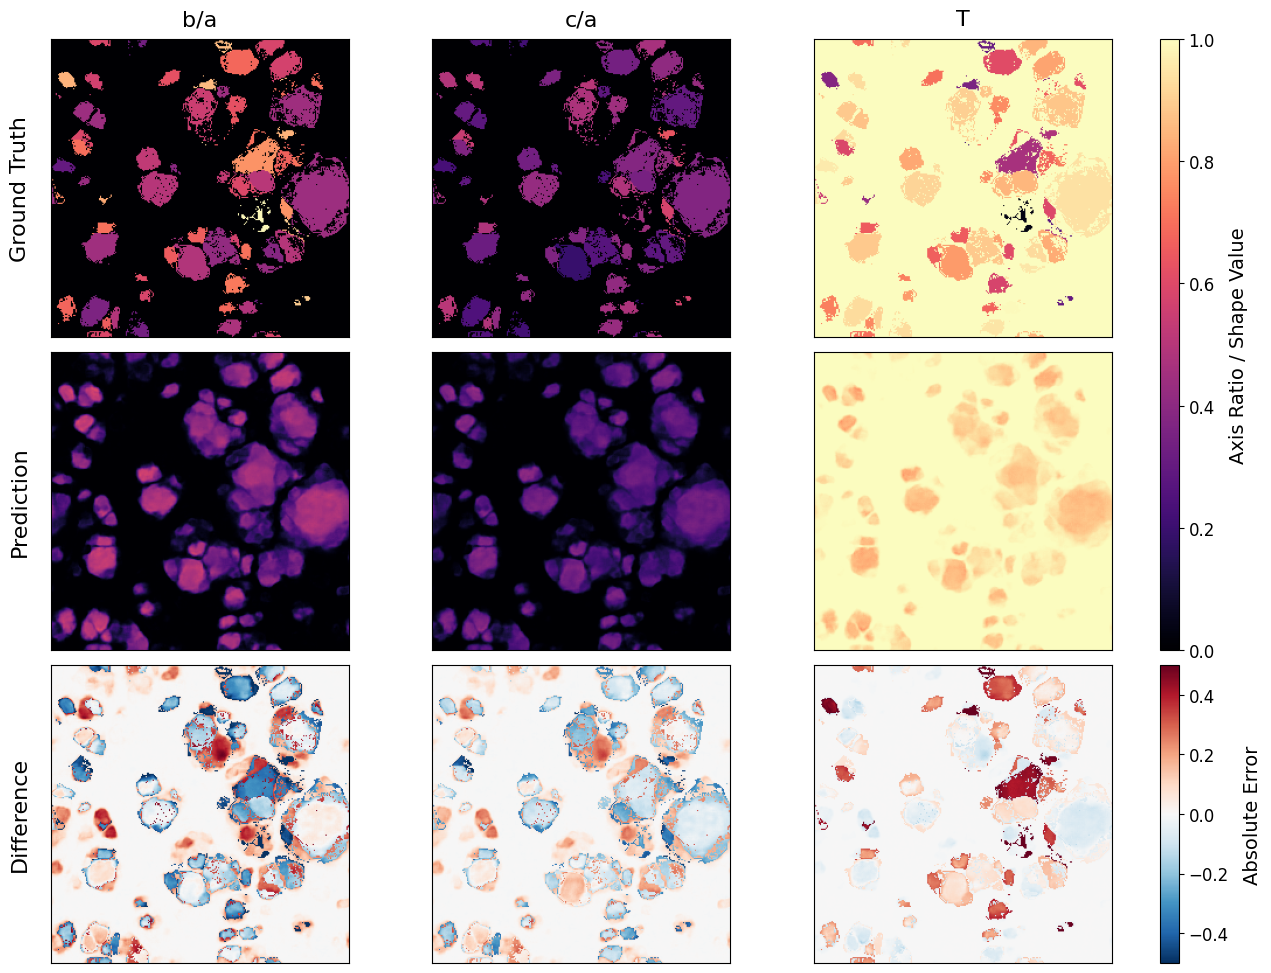

In [13]:
# plot comparing a slice of the initial density field vs the ground truth and the prediction by the model

x0, y0, mask0, sim_path0 = test_ds[1]
pred0 = predict_volume(model, x0)  # (2, D, H, W)

D = x0.shape[1]
slice_idx = D // 2

mask0_np = mask0.squeeze(0)[slice_idx].numpy().astype(bool)

#get 2D slices
gt_ba_slice = y0[0, slice_idx].numpy()
gt_ca_slice = y0[1, slice_idx].numpy()

pred_ba_slice = pred0[0, slice_idx].numpy()
pred_ca_slice = pred0[1, slice_idx].numpy()

#compute triaxiality
triax_gt_slice = (1 - gt_ba_slice**2) / (1 - gt_ca_slice**2 + 1e-10)
triax_pred_slice = (1 - pred_ba_slice**2) / (1 - pred_ca_slice**2 + 1e-10)

#compute differences
diff_ba = pred_ba_slice - gt_ba_slice
diff_ca = pred_ca_slice - gt_ca_slice
diff_triax = triax_pred_slice - triax_gt_slice


fig = plt.figure(figsize=(15, 12), constrained_layout=True)
gs = GridSpec(3, 4, width_ratios=[1, 1, 1, 0.05], hspace=0.05, wspace=0.05)


axes = np.empty((3, 3), dtype=object)
for r in range(3):
    for c in range(3):
        axes[r, c] = fig.add_subplot(gs[r, c])

#truth
im00 = axes[0, 0].imshow(gt_ba_slice, cmap="magma", vmin=0, vmax=1)
axes[0, 0].set_title("b/a", fontsize=16, pad=10)
axes[0, 0].set_xticks([])
axes[0, 0].set_yticks([])

im01 = axes[0, 1].imshow(gt_ca_slice, cmap="magma", vmin=0, vmax=1)
axes[0, 1].set_title("c/a", fontsize=16, pad=10)
axes[0, 1].set_xticks([])
axes[0, 1].set_yticks([])

im02 = axes[0, 2].imshow(triax_gt_slice, cmap="magma", vmin=0, vmax=1)
axes[0, 2].set_title("T", fontsize=16, pad=10)
axes[0, 2].set_xticks([])
axes[0, 2].set_yticks([])

axes[0,0].set_ylabel("Ground Truth", fontsize=16, labelpad=15)


#prediction
im10 = axes[1, 0].imshow(pred_ba_slice, cmap="magma", vmin=0, vmax=1)
axes[1, 0].set_xticks([])
axes[1, 0].set_yticks([])

im11 = axes[1, 1].imshow(pred_ca_slice, cmap="magma", vmin=0, vmax=1)
axes[1, 1].set_xticks([])
axes[1, 1].set_yticks([])

im12 = axes[1, 2].imshow(triax_pred_slice, cmap="magma", vmin=0, vmax=1)
axes[1, 2].set_xticks([])
axes[1, 2].set_yticks([])

axes[1,0].set_ylabel("Prediction", fontsize=16, labelpad=15)

#difference
im20 = axes[2, 0].imshow(diff_ba, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[2, 0].set_xticks([])
axes[2, 0].set_yticks([])

im21 = axes[2, 1].imshow(diff_ca, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[2, 1].set_xticks([])
axes[2, 1].set_yticks([])

im22 = axes[2, 2].imshow(diff_triax, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[2, 2].set_xticks([])
axes[2, 2].set_yticks([])

axes[2,0].set_ylabel("Difference", fontsize=16, labelpad=15)


#colorbars
cax_top = fig.add_subplot(gs[0:2, -1])
cb_top = fig.colorbar(im12, cax=cax_top, orientation="vertical")
cb_top.ax.tick_params(labelsize=12)
cb_top.set_label("Axis Ratio / Shape Value", fontsize=14, labelpad=10)

cax_bottom = fig.add_subplot(gs[2, -1])
cb_bottom = fig.colorbar(im22, cax=cax_bottom, orientation="vertical")
cb_bottom.ax.tick_params(labelsize=12)
cb_bottom.set_label("Absolute Error", fontsize=14, labelpad=10)

plt.show()

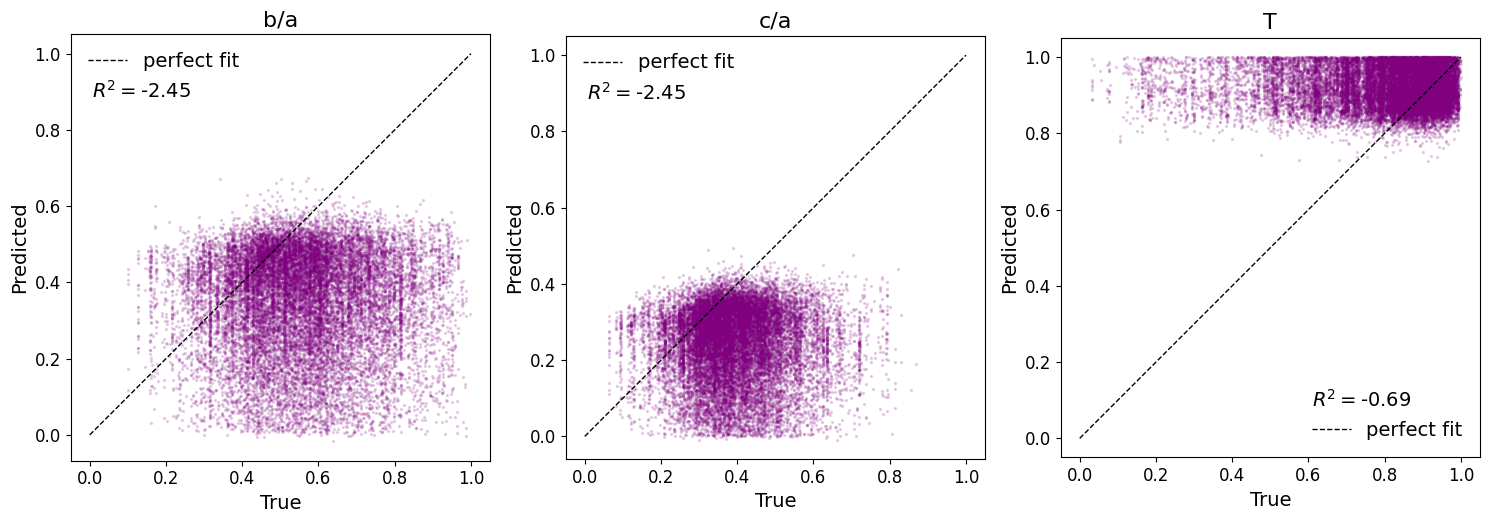

In [14]:
#plot the scatter comparison

model.eval()

gt_ba, pred_ba = [], []
gt_ca, pred_ca = [], []
gt_t, pred_t = [] , []

with torch.no_grad():
    for x, y, mask, sim in test_loader:  
        x0 = x.squeeze(0)         
        pred = predict_volume(model, x0)  

        mask_np = mask.squeeze(0).squeeze(0).numpy().astype(bool) 
        y_np = y.squeeze(0).numpy()       
        pred_np = pred.numpy()            

        #get masked foreground pixels
        ba_gt_m = y_np[0][mask_np]
        ba_pred_m = pred_np[0][mask_np]
        
        ca_gt_m = y_np[1][mask_np]
        ca_pred_m = pred_np[1][mask_np]

        #calculate triaxiality on masked pixels
        t_gt_m = (1 - ba_gt_m**2) / (1 - ca_gt_m**2 + 1e-10)
        t_pred_m = (1 - ba_pred_m**2) / (1 - ca_pred_m**2 + 1e-10)

        gt_ba.append(ba_gt_m)
        pred_ba.append(ba_pred_m)
        gt_ca.append(ca_gt_m)
        pred_ca.append(ca_pred_m)
        gt_t.append(t_gt_m)
        pred_t.append(t_pred_m)

#concatenate all test simulations into flat arrays
gt_ba = np.concatenate(gt_ba)
pred_ba = np.concatenate(pred_ba)
gt_ca = np.concatenate(gt_ca)
pred_ca = np.concatenate(pred_ca)
gt_t = np.concatenate(gt_t)
pred_t = np.concatenate(pred_t)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

gts = [gt_ba, gt_ca, gt_t]
preds = [pred_ba, pred_ca, pred_t]
titles = ["b/a", "c/a", "T"]

for i, (gt, pred, title) in enumerate(zip(gts, preds, titles)):
    idx = np.random.choice(len(gt), 20000, replace=False)
    gt_s = gt[idx]
    pred_s = pred[idx]

    r2 = r2_score(gt, pred)

    axes[i].scatter(gt_s, pred_s, s=2, alpha=0.15, color="purple")
    axes[i].plot([0,1], [0,1], color="black", linestyle="--", linewidth=1, label="perfect fit")
    axes[i].set_xlabel("True", fontsize=14)
    axes[i].set_ylabel("Predicted", fontsize=14)
    axes[i].tick_params(labelsize=12)
    axes[i].set_title(title, fontsize=16)
   
    if title == "T":
        axes[i].legend(loc="lower right", frameon=False, fontsize=14)
        axes[i].text(0.6, 0.12, f"$R^2=${r2:.2f}", fontsize=14, transform=axes[i].transAxes)
    else: 
        axes[i].legend(loc="upper left", frameon=False, fontsize=14)
        axes[i].text(0.05, 0.85, f"$R^2=${r2:.2f}", fontsize=14, transform=axes[i].transAxes)
    axes[i].set_aspect("equal")

plt.tight_layout()
plt.show()

In [15]:
#compute binary classification

gt_ba_3d = y0[0].numpy()
pred_ba_3d = pred0[0].cpu().numpy()

true_background_mask_3d = (gt_ba_3d == 0.0)
true_halo_mask_3d = (gt_ba_3d > 0.0)

threshold = 0.05
pred_background_mask_3d = pred_ba_3d < threshold
pred_halo_mask_3d = pred_ba_3d >= threshold

TN_global = np.sum(true_background_mask_3d & pred_background_mask_3d)
FP_global = np.sum(true_background_mask_3d & pred_halo_mask_3d)
TP_global = np.sum(true_halo_mask_3d & pred_halo_mask_3d)
FN_global = np.sum(true_halo_mask_3d & pred_background_mask_3d)

TPR_global = TP_global/(TP_global + FN_global)
TNR_global = TN_global/(TN_global + FP_global)
PPV_global = TP_global/(TP_global + FP_global)
acc_global = (TP_global + TN_global)/(TP_global + TN_global + FN_global + FP_global)
F1_global = 2*TP_global/(2*TP_global + FP_global + FN_global)

print("TPR:", TPR_global)
print("TNR:", TNR_global)
print("PPV:", PPV_global)
print("Accuracy", acc_global)
print("F1:", F1_global)


TPR: 0.9758783660847792
TNR: 0.7358672261145558
PPV: 0.5241238363110676
Accuracy 0.7909846305847168
F1: 0.6819738160229079


#### Overfit single simulation

In [ ]:
#overfit model with one simulation
model_overfit = VNetShape(out_ch=OUT_CH, dropout=0.0).to(device, memory_format=torch.channels_last_3d)
model_overfit.train()

x, y, mask = train_ds[0]
x, y, mask = x.unsqueeze(0), y.unsqueeze(0), mask.unsqueeze(0)
x, y, mask = x.to(device), y.to(device), mask.to(device)

optimizer = torch.optim.Adam(model_overfit.parameters(), lr=1e-4)
losses = []

for step in range(3000):
    optimizer.zero_grad()
    pred = model_overfit(x)
    mse_ba, mse_ca = mse_loss_per_channel(pred, y)
    loss = mse_ba + mse_ca 
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if step%100==0:
        print(f"step {step:5d}  loss={loss.item():.6f}")
        print(f"(ba={mse_ba.item():.6f}, ca={mse_ca.item():.6f})")


In [ ]:
#save model 
best_state = {"state_dict": {k: v.cpu().clone() for k, v in model_overfit.state_dict().items()},
            "loss_history": list(losses), 
            "x": x,
            "y": y,
            "mask": mask}

torch.save(best_state, "model_overfitting.pt")

In [16]:
#load the model
checkpoint = torch.load("model_overfitting.pt", map_location=device)

model_overfit = VNetShape(out_ch=OUT_CH, dropout=0.0).to(device, memory_format=torch.channels_last_3d)
model_overfit.load_state_dict(checkpoint["state_dict"])
model_overfit.eval()

#extract saved weights 
x = checkpoint["x"].to(device)
y = checkpoint["y"].to(device)
mask = checkpoint["mask"].to(device)
losses = checkpoint["loss_history"]

#predictions
with torch.no_grad():
    pred = model_overfit(x)

fg = mask[:, 0].bool().cpu().numpy()
pred_np = pred.cpu().numpy()
true_np = y.cpu().numpy()

pred_ba = pred_np[:, 0][fg]
pred_ca = pred_np[:, 1][fg]
true_ba = true_np[:, 0][fg]
true_ca = true_np[:, 1][fg]

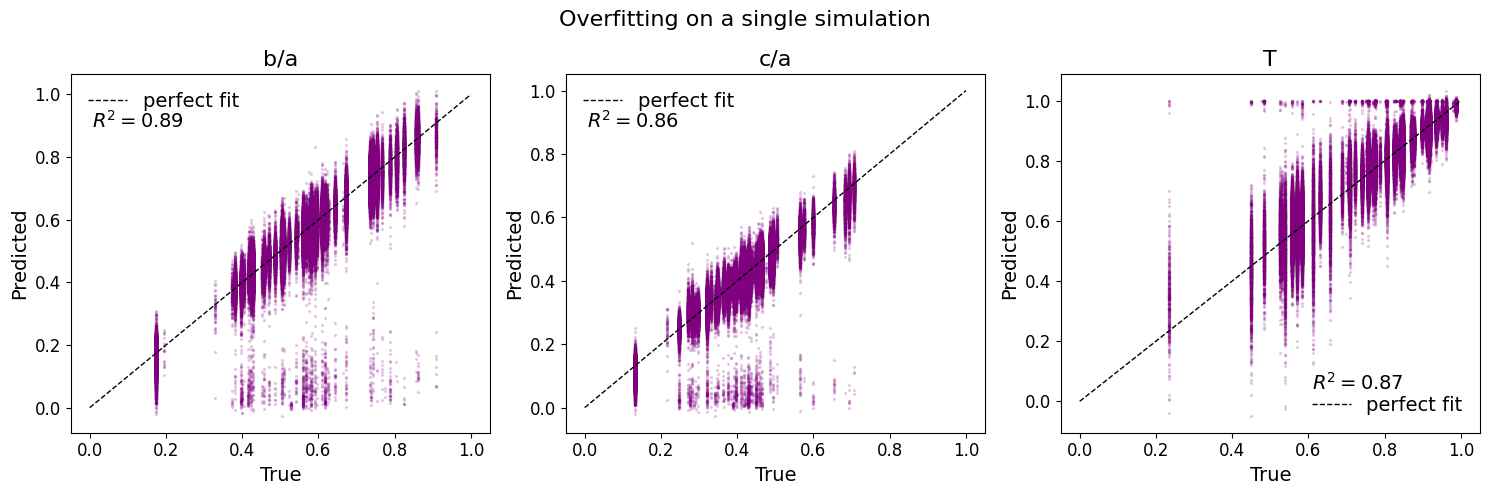

In [17]:
#plot the models prediction
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

t_gt = (1 - true_ba**2) / (1 - true_ca**2 + 1e-10)
t_pred = (1 - pred_ba**2) / (1 - pred_ca**2 + 1e-10)
gts = [true_ba, true_ca, t_gt]
preds = [pred_ba, pred_ca, t_pred]

titles = ["b/a", "c/a", "T"]

for i, (gt, pred, title) in enumerate(zip(gts, preds, titles)):
    gt_s = gt
    pred_s = pred

    r2 = r2_score(gt, pred)

    axes[i].scatter(gt_s, pred_s, s=2, alpha=0.15, color="purple")
    axes[i].plot([0,1], [0,1], color="black", linestyle="--", linewidth=1, label="perfect fit")
    axes[i].set_xlabel("True", fontsize=14)
    axes[i].set_ylabel("Predicted", fontsize=14)
    axes[i].tick_params(labelsize=12)
    axes[i].set_title(title, fontsize=16)
   
    if title == "T":
        axes[i].legend(loc="lower right", frameon=False, fontsize=14)
        axes[i].text(0.6, 0.12, f"$R^2=${r2:.2f}", fontsize=14, transform=axes[i].transAxes)
    else: 
        axes[i].legend(loc="upper left", frameon=False, fontsize=14)
        axes[i].text(0.05, 0.85, f"$R^2=${r2:.2f}", fontsize=14, transform=axes[i].transAxes)

plt.suptitle("Overfitting on a single simulation", fontsize=16)
plt.tight_layout()
plt.show()

## Axis ratio prediction only

In [18]:
class ShapeTrainDataset(Dataset):
    """
    Loading all trainings data file from root directory (density field, labels). Random cropping to a cube of size cube_size for each simulation.
    Random data augmentation via flipping and 90 degree rotation.
    Normalization based on the full trainings data mean and variance (z-score).
    """

    def __init__(self, root_dir, cube_size=96, augment=True,
                 cache_mode="mmap"):
        self.root_dir = root_dir
        self.cube_size = cube_size
        self.augment = augment
        self.cache_mode = cache_mode

        self.sims = [
            os.path.join(root_dir, sim)
            for sim in os.listdir(root_dir)
            if os.path.isdir(os.path.join(root_dir, sim))
        ] #contains all the simulations from the root training folder

    def __len__(self):
        return len(self.sims)

    def _find_file(self, sim_path, prefix):
        for f in os.listdir(sim_path):
            if f.startswith(prefix):
                return os.path.join(sim_path, f)
        raise FileNotFoundError(f"No file starting with '{prefix}' in {sim_path}")

    def load_sim(self, sim_path):
        density_path = self._find_file(sim_path, "density_")
        label_path_ba = self._find_file(sim_path, "label_ba_")
        label_path_ca = self._find_file(sim_path, "label_ca_")


        if self.cache_mode == "mmap": #memory efficient for large objects like simulation cubes
            density = np.load(density_path, mmap_mode="r")
            labels_ba = np.load(label_path_ba, mmap_mode="r")
            labels_ca = np.load(label_path_ca, mmap_mode="r")

        else: 
            density = np.load(density_path)
            labels_ba = np.load(label_path_ba)
            labels_ca = np.load(label_path_ca)
        
        labels = np.stack([labels_ba, labels_ca], axis=0)

        return density, labels

    def normalize(self, x): # normalization (z-score) via the calulated mean density and the variance between the simulation training set
        return (x - DENSITY_MEAN) / (DENSITY_STD + 1e-8)
    
    def random_crop(self, x, y):
        c = self.cube_size
        X, Y, Z = x.shape
        #selecting random window starting point 
        x0 = random.randint(0, X - 1)
        y0 = random.randint(0, Y - 1)
        z0 = random.randint(0, Z - 1)

        #wrapping if the crop window would go across the boundary
        idx_x = np.arange(x0, x0 + c) % X
        idx_y = np.arange(y0, y0 + c) % Y
        idx_z = np.arange(z0, z0 + c) % Z

        x_crop = x[np.ix_(idx_x, idx_y, idx_z)]

        idx_c = np.arange(y.shape[0])
        y_crop =  y[np.ix_(idx_c, idx_x, idx_y, idx_z)]

        return x_crop, y_crop

    #randoming flipping  along any of the three axis both density and labels
    def random_flip(self, x, y):
        for ax in [0, 1, 2]:
            if random.random() < 0.5:
                x = np.flip(x, axis=ax)
                y = np.flip(y, axis=ax+1)
        return x, y

    #randomly rotating by multiples of 90 degrees at a random axis both density and labels
    def random_rot90(self, x, y):
        k = random.randint(0, 3)
        axes = random.choice([(0, 1), (0, 2), (1, 2)])
        x = np.rot90(x, k, axes)
        y = np.rot90(y, k, tuple(a+1 for a in axes))
        return x, y

    def __getitem__(self, idx):
        sim = self.sims[idx]
        x, y = self.load_sim(sim)

        x_crop, y_crop = self.random_crop(x, y)
        x_crop = self.normalize(x_crop)

        if self.augment:
            x_crop, y_crop = self.random_flip(x_crop, y_crop)
            x_crop, y_crop = self.random_rot90(x_crop, y_crop)

        #change all labels that are originally nan (background) to 0.0 & save mask for all particles originally in halos
        mask_crop = ~np.isnan(y_crop[0])
        y_clean = np.nan_to_num(y_crop, nan=0.0)

        x_t = torch.from_numpy(x_crop.copy()).float().unsqueeze(0)
        y_t = torch.from_numpy(y_clean.copy()).float()
        mask_t = torch.from_numpy(mask_crop.copy()).float().unsqueeze(0)
        return x_t, y_t, mask_t 


class ShapeTestDataset(Dataset):
    """
    Similar to the CosmologyTrainingDataset but for the test/validation case no random cropping or data augmentation.
    normalization based on the trainings data global mean and variance.
    
    """

    def __init__(self, root_dir):
        self.root_dir = root_dir
        self.sims = [
            os.path.join(root_dir, sim)
            for sim in os.listdir(root_dir)
            if os.path.isdir(os.path.join(root_dir, sim))
        ]

    def __len__(self):
        return len(self.sims)

    def load_sim(self, sim_path):
        density_file = [f for f in os.listdir(sim_path) if f.startswith("density_")][0]
        label_file_ba = [f for f in os.listdir(sim_path) if f.startswith("label_ba_")][0]
        label_file_ca = [f for f in os.listdir(sim_path) if f.startswith("label_ca_")][0]

        density = np.load(os.path.join(sim_path, density_file))
        labels_ba = np.load(os.path.join(sim_path, label_file_ba))
        labels_ca = np.load(os.path.join(sim_path, label_file_ca))

        labels = np.stack([labels_ba, labels_ca], axis=0)

        return density, labels

    def normalize(self, x):
        return  (x - DENSITY_MEAN) / (DENSITY_STD + 1e-8)

    def __getitem__(self, idx):
        sim = self.sims[idx]
        x, y = self.load_sim(sim)
        x = self.normalize(x)

        #change all labels that are originally nan (background) to 0.0 & save mask for all particles originally in halos
        mask = ~np.isnan(y[0])
        y_clean = np.nan_to_num(y, nan=0.0)

        x_t = torch.from_numpy(x.copy()).float().unsqueeze(0)
        y_t = torch.from_numpy(y_clean.copy()).float()
        mask_t = torch.from_numpy(mask.copy()).float().unsqueeze(0)
        return x_t, y_t, mask_t, sim

In [19]:
OUT_CH = 2 #number of channels for the network to return: b/a and c/a
CUBE_SIZE = 80 #the subvolume used for training due to limited gpu ram
BATCH_SIZE = 8 # batchsize for training
NUM_WORKERS = 8

train_ds = ShapeTrainDataset(DATA_ROOT, cube_size=CUBE_SIZE, augment=True, cache_mode="mmap")

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    shuffle=True,
    pin_memory=True,
    persistent_workers=True,
)

val_ds   = ShapeTestDataset(VAL_ROOT)
val_loader = DataLoader(val_ds, batch_size=1, num_workers=1, shuffle=False)

test_ds = ShapeTestDataset(TEST_ROOT)
test_loader = DataLoader(test_ds, batch_size=1, num_workers=1, shuffle=False)

print(f"Train sims: {len(train_ds.sims)}")
print(f"Test volumes: {len(test_ds)}") 
print(f"Validation volumes: {len(val_ds)}")

Train sims: 90
Test volumes: 10
Validation volumes: 10


In [20]:
# define a classical convolution operator
# with in channels and out channels
#this operator keeps the spatial dimension the same 
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, 3, padding=1, padding_mode="circular"), #3d conv operation with a 3x3x3 filter kernel and padding 1, the padding is applied circular concistent with simulations
            nn.LeakyReLU(0.05, inplace=True), #activation function leakyrelu for nonlinearity
            nn.Conv3d(out_ch, out_ch, 3, padding=1, padding_mode="circular"),  #3d conv operation with a 3x3x3 filter kernel and padding 1, the padding is applied circular concistent with simulations
            nn.LeakyReLU(0.05, inplace=True),  #activation function leakyrelu for nonlinearity
        )

    def forward(self, x):
        return self.net(x)


class VNetShape(nn.Module):
    def __init__(self, in_ch=1, out_ch=2, base=32, dropout=0): #no dropout!
        super().__init__()

        #encoder
        self.enc1 = ConvBlock(in_ch, base) #start with normal convolutional operation on the full volume of the sim -> increasing filter depth
        self.drop1 = nn.Dropout3d(dropout) #apply dropout to avoid overfitting
        self.pool1 = nn.MaxPool3d(2) #max pooling to reduce the spatial size of the cube for the next layer (by half)

        self.enc2 = ConvBlock(base, base * 2) #repeating decoding block now further increasing the filter depth
        self.drop2 = nn.Dropout3d(dropout)
        self.pool2 = nn.MaxPool3d(2)

        self.enc3 = ConvBlock(base * 2, base * 4) #again
        self.drop3 = nn.Dropout3d(dropout)
        self.pool3 = nn.MaxPool3d(2)

        self.bottleneck = ConvBlock(base * 4, base * 8) # maximum compression (bottleneck)
 
        #decoder
        self.up3 = nn.ConvTranspose3d(base * 8, base * 4, 2, stride=2) # conv transpose with stride to essentially increasing (doubling) the spatial dimensions adn using a filter of size 2x2x2
        self.dec3 = ConvBlock(base * 8, base * 4) #classic convolution operation now decreasing the filter depth again

        self.up2 = nn.ConvTranspose3d(base * 4, base * 2, 2, stride=2) #again repeat doubling spatial dimension halfing the channel depth
        self.dec2 = ConvBlock(base * 4, base * 2)

        self.up1 = nn.ConvTranspose3d(base * 2, base, 2, stride=2)
        self.dec1 = ConvBlock(base * 2, base)

        self.out = nn.Conv3d(base, out_ch, 1) # final output must be a value for each of the class numbers, by using a 1x1x1 kernel to make prediction for each voxel

    def forward(self, x):
        x1 = self.enc1(x) #encoding 1
        x2 = self.enc2(self.pool1(self.drop1(x1))) #pooling and encoding
        x3 = self.enc3(self.pool2(self.drop2(x2))) # pooling and encoding
        x4 = self.bottleneck(self.pool3(self.drop3(x3))) #pooling and bottleneck

        y3 = self.dec3(torch.cat([self.up3(x4), x3], dim=1)) # concatenate (skip connection between the different unet depth layers) then decoding
        # up3(x4) has base*4 channels, x3 (skip) has base*4 channels concatenated -> base*8 channels in, base*4 channels out (per ConvBlock def)
        y2 = self.dec2(torch.cat([self.up2(y3), x2], dim=1)) #skip connectors and decodin
        y1 = self.dec1(torch.cat([self.up1(y2), x1], dim=1)) #skip connectors and decodin

        return self.out(y1) #output in (0,1)
        #return torch.nn.functional.hardsigmoid(self.out(y1))


#loss function for masked background particles 
def mse_loss_per_channel_masked(pred, target, mask, eps=1e-6):
    mask_expanded = mask.expand_as(pred)
    squared_err = (pred-target)**2 * mask_expanded
    mse_ba  = squared_err[:,0].sum() / (mask.sum() + eps)
    mse_ca  = squared_err[:,1].sum() / (mask.sum() + eps)
    return mse_ba, mse_ca

In [21]:
torch.backends.cudnn.benchmark = True
device = "cuda" if torch.cuda.is_available() else "cpu"

MAX_NUM_EPOCHS = 1000
LR = 1e-4
model_masked = VNetShape(out_ch=OUT_CH).to(device, memory_format=torch.channels_last_3d)

start_epoch = 0
early_stopper = EarlyStopper(patience=40, min_delta=1e-4) #initialize early stop
opt = torch.optim.Adam(model_masked.parameters(), lr=LR) #set optimizer and learning rate
scaler = torch.amp.GradScaler("cuda")  #gradient scaler for mixed-precision trainin

In [ ]:
loss_history = []
val_loss_history = []

for epoch in range(MAX_NUM_EPOCHS):
    model_masked.train()
    running_loss = 0.0
    t0 = time.time()

    #training
    for x, y, mask in train_loader: #iterate over the batches loaded from the training set
        x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last_3d) #move input batch to the GPU
        y = y.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)

        opt.zero_grad(set_to_none=True)  #clear gradients

        with torch.amp.autocast("cuda"):
            pred = model_masked(x) #forward pass through network prediction
            mse_ba, mse_ca = mse_loss_per_channel_masked(pred, y, mask)
            loss = mse_ba + mse_ca  #calculate loss 
            del mse_ba, mse_ca #free ip memory

        scaler.scale(loss).backward() #backwards compute gradients
        scaler.step(opt) #optimizer update
        scaler.update() #update loss scaling factor
        running_loss += loss.item() #add loss
        
        del x, y, mask, pred, loss #free up memory

    train_epoch_loss = running_loss / len(train_loader)
    loss_history.append(train_epoch_loss)

    #validation
    model_masked.eval()
    running_val_loss = 0.0
    with torch.no_grad(): #no gradiant calculation for validation
        for x, y, mask, _ in val_loader:#go through the 10 validation simulations (batchsize=1)
            x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last_3d)   #send to gpu
            y = y.to(device, non_blocking=True)
            mask = mask.to(device, non_blocking=True)

            pred = model_masked(x) #evaluate
            val_mse_ba, val_mse_ca = mse_loss_per_channel_masked(pred, y, mask) #loss
            val_loss = val_mse_ba + val_mse_ca
            running_val_loss += val_loss.item()

            del x, y, mask, pred, val_loss #free up memory

    val_epoch_loss = running_val_loss / len(val_loader)
    val_loss_history.append(val_epoch_loss)

    dt = time.time() - t0
    print(f"Epoch {epoch}")
    print(f"Train_loss={train_epoch_loss:.4f}  val_loss={val_epoch_loss:.4f}  ({dt:.1f}s)")

    #check if model has improved in this epoch
    improved = early_stopper.step(val_epoch_loss)
    if improved:
        best_state = {
            "state_dict": {k: v.cpu().clone() for k, v in model_masked.state_dict().items()},
            "loss_history": list(loss_history),          
            "val_loss_history": list(val_loss_history),  
            "epoch": epoch}

    if early_stopper.should_stop:
        print(f"Early stopping at epoch {epoch} (no improvement for {early_stopper.patience} epochs)")
        break

In [ ]:
#save the model
torch.save(best_state, "model_best_masked_nosigmoid_nodropout.pt")

In [22]:
#load model
device = "cuda" if torch.cuda.is_available() else "cpu"
model_masked = VNetShape(out_ch=OUT_CH).to(device, memory_format=torch.channels_last_3d)

checkpoint = torch.load("model_best_masked_nosigmoid_nodropout.pt", map_location=device)
model_masked.load_state_dict(checkpoint["state_dict"])

model_masked.to(device)

VNetShape(
  (enc1): ConvBlock(
    (net): Sequential(
      (0): Conv3d(1, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (1): LeakyReLU(negative_slope=0.05, inplace=True)
      (2): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (3): LeakyReLU(negative_slope=0.05, inplace=True)
    )
  )
  (drop1): Dropout3d(p=0, inplace=False)
  (pool1): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): ConvBlock(
    (net): Sequential(
      (0): Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (1): LeakyReLU(negative_slope=0.05, inplace=True)
      (2): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (3): LeakyReLU(negative_slope=0.05, inplace=True)
    )
  )
  (drop2): Dropout3d(p=0, inplace=False)
  (pool2): MaxPool3d(kernel_size=2, stride=2, padding=

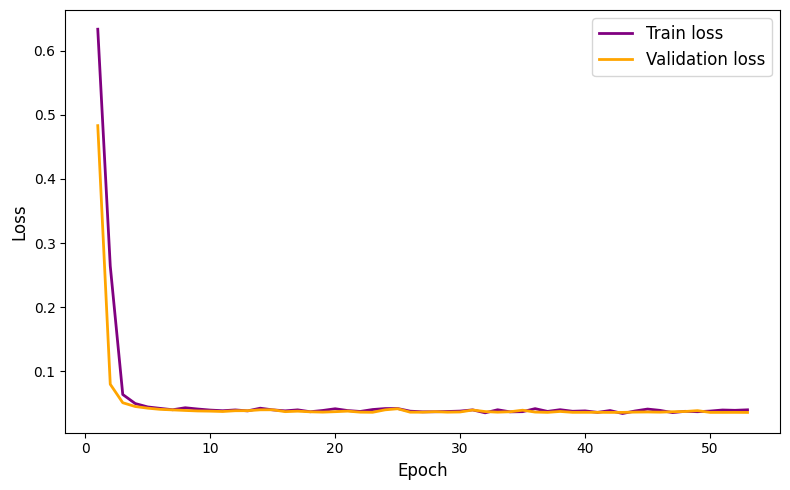

In [23]:
#plot loss history
loss_history = checkpoint["loss_history"]
val_loss_history = checkpoint["val_loss_history"]

epochs = range(1, len(loss_history) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, loss_history, label="Train loss", color="purple", lw=2)
plt.plot(epochs, val_loss_history, label="Validation loss", color="orange", lw=2)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

In [24]:
model_masked.eval()

VNetShape(
  (enc1): ConvBlock(
    (net): Sequential(
      (0): Conv3d(1, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (1): LeakyReLU(negative_slope=0.05, inplace=True)
      (2): Conv3d(32, 32, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (3): LeakyReLU(negative_slope=0.05, inplace=True)
    )
  )
  (drop1): Dropout3d(p=0, inplace=False)
  (pool1): MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2): ConvBlock(
    (net): Sequential(
      (0): Conv3d(32, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (1): LeakyReLU(negative_slope=0.05, inplace=True)
      (2): Conv3d(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), padding_mode=circular)
      (3): LeakyReLU(negative_slope=0.05, inplace=True)
    )
  )
  (drop2): Dropout3d(p=0, inplace=False)
  (pool2): MaxPool3d(kernel_size=2, stride=2, padding=

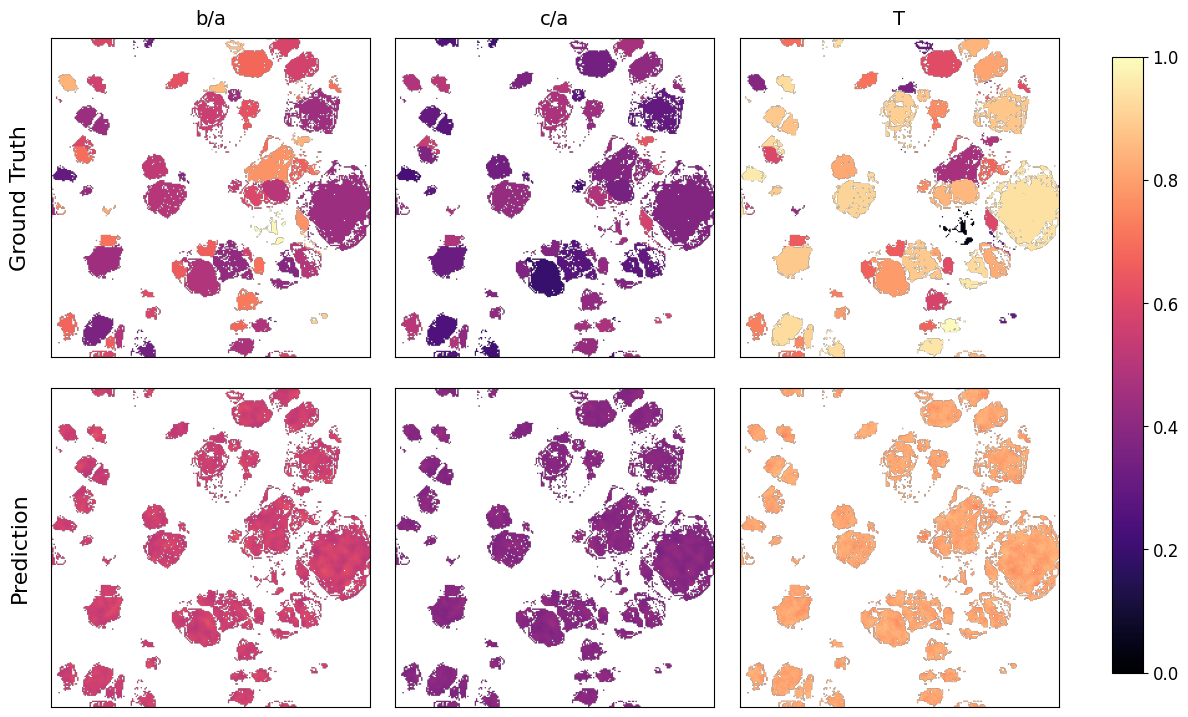

In [25]:
#plot the prediction for one slice

x0, y0, mask0, sim_path0 = test_ds[1]
pred0 = predict_volume(model_masked, x0) 

D = x0.shape[1]
slice_idx = D // 2

mask0_np = mask0.squeeze(0)[slice_idx].numpy().astype(bool)

# get 2D slices first
gt_ba_slice = y0[0, slice_idx].numpy()
gt_ca_slice = y0[1, slice_idx].numpy()

pred_ba_slice = pred0[0, slice_idx].numpy()
pred_ca_slice = pred0[1, slice_idx].numpy()

#change background to nan
gt_ba_masked = np.where(mask0_np, gt_ba_slice, np.nan)
gt_ca_masked = np.where(mask0_np, gt_ca_slice, np.nan)

pred_ba_masked = np.where(mask0_np, pred_ba_slice, np.nan)
pred_ca_masked = np.where(mask0_np, pred_ca_slice, np.nan)

#compute triaxiality on masked slices
triax_gt_slice = (1 - gt_ba_masked**2) / (1 - gt_ca_masked**2 + 1e-10)
triax_pred_slice = (1 - pred_ba_masked**2) / (1 - pred_ca_masked**2 + 1e-10)




fig, axes = plt.subplots(2, 3, figsize=(14, 8))

#plot truth
im00 = axes[0, 0].imshow(gt_ba_masked, cmap="magma", vmin=0, vmax=1)
axes[0, 0].set_title("b/a", fontsize=14, pad=10)
axes[0, 0].set_xticks([])
axes[0, 0].set_yticks([])

im01 = axes[0, 1].imshow(gt_ca_masked, cmap="magma", vmin=0, vmax=1)
axes[0, 1].set_title("c/a", fontsize=14, pad=10)
axes[0, 1].set_xticks([])
axes[0, 1].set_yticks([])


im02 = axes[0, 2].imshow(triax_gt_slice, cmap="magma", vmin=0, vmax=1)
axes[0, 2].set_title("T", fontsize=14, pad=10)
axes[0, 2].set_xticks([])
axes[0, 2].set_yticks([])

#plot prediction 
im10 = axes[1, 0].imshow(pred_ba_masked, cmap="magma", vmin=0, vmax=1)
axes[1, 0].set_xticks([])
axes[1, 0].set_yticks([])

im11 = axes[1, 1].imshow(pred_ca_masked, cmap="magma", vmin=0, vmax=1)
axes[1, 1].set_xticks([])
axes[1, 1].set_yticks([])

im12 = axes[1, 2].imshow(triax_pred_slice, cmap="magma", vmin=0, vmax=1)
axes[1, 2].set_xticks([])
axes[1, 2].set_yticks([])

axes[0,0].set_ylabel("Ground Truth", fontsize=16, labelpad=15)
axes[1,0].set_ylabel("Prediction", fontsize=16, labelpad=15)


cbar = fig.colorbar(im12, ax=axes.ravel(), fraction=0.08, pad=0.01)
cbar.ax.tick_params(labelsize=12)

plt.subplots_adjust(left=0.08, right=0.8, top=0.92, bottom=0.05, wspace=0.08, hspace=0.01)
plt.show()

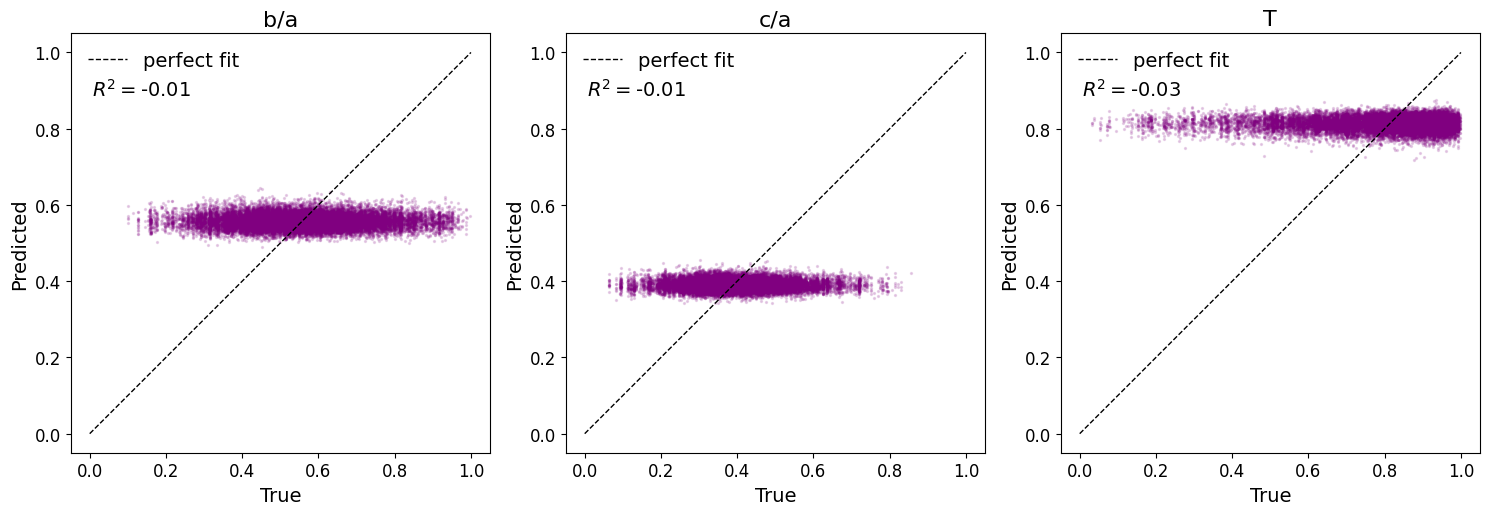

In [26]:
#plot scatter results

model_masked.eval()

gt_ba, pred_ba = [], []
gt_ca, pred_ca = [], []
gt_t, pred_t = [] , []

with torch.no_grad():
    for x, y, mask, sim in test_loader:
        x0 = x.squeeze(0)         
        pred = predict_volume(model_masked, x0)  

        mask_np = mask.squeeze(0).squeeze(0).numpy().astype(bool) 
        y_np = y.squeeze(0).numpy()        
        pred_np = pred.numpy()             

        ba_gt_m = y_np[0][mask_np]
        ba_pred_m = pred_np[0][mask_np]
        
        ca_gt_m = y_np[1][mask_np]
        ca_pred_m = pred_np[1][mask_np]

        #calculate triaxiality on masked pixels
        t_gt_m = (1 - ba_gt_m**2) / (1 - ca_gt_m**2 + 1e-10)
        t_pred_m = (1 - ba_pred_m**2) / (1 - ca_pred_m**2 + 1e-10)

        gt_ba.append(ba_gt_m)
        pred_ba.append(ba_pred_m)
        gt_ca.append(ca_gt_m)
        pred_ca.append(ca_pred_m)
        gt_t.append(t_gt_m)
        pred_t.append(t_pred_m)

#concatenate test simulations into flat arrays
gt_ba = np.concatenate(gt_ba)
pred_ba = np.concatenate(pred_ba)
gt_ca = np.concatenate(gt_ca)
pred_ca = np.concatenate(pred_ca)
gt_t = np.concatenate(gt_t)
pred_t = np.concatenate(pred_t)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

gts = [gt_ba, gt_ca, gt_t]
preds = [pred_ba, pred_ca, pred_t]
titles = ["b/a", "c/a", "T"]

for i, (gt, pred, title) in enumerate(zip(gts, preds, titles)):
    idx = np.random.choice(len(gt), 20000, replace=False)
    gt_s = gt[idx]
    pred_s = pred[idx]

    r2 = r2_score(gt, pred)

    axes[i].scatter(gt_s, pred_s, s=2, alpha=0.15, color="purple")
    axes[i].plot([0,1], [0,1], color="black", linestyle="--", linewidth=1, label="perfect fit")
    axes[i].set_xlabel("True", fontsize=14)
    axes[i].set_ylabel("Predicted", fontsize=14)
    axes[i].tick_params(labelsize=12)
    axes[i].set_title(title, fontsize=16)
    axes[i].legend(loc="upper left", frameon=False, fontsize=14)
    axes[i].text(0.05, 0.85, f"$R^2=${r2:.2f}", fontsize=14, transform=axes[i].transAxes)
    axes[i].set_aspect("equal")

plt.tight_layout()
plt.show()

In [27]:
#print mean and std for truth and predictions

print("b/a: mean", gt_ba.mean())
print("b/a: std", gt_ba.std())

print("pred b/a: mean", pred_ba.mean())
print("pred b/a: mean std", pred_ba.std())
print("\n")

print("c/a: mean", gt_ca.mean())
print("c/a: std", gt_ca.std())

print("pred c/a: mean", pred_ca.mean())
print("pred c/a: std", pred_ca.std())

b/a: mean 0.5547031
b/a: std 0.15759985
pred b/a: mean 0.55737746
pred b/a: mean std 0.018422615


c/a: mean 0.3921838
c/a: std 0.11274463
pred c/a: mean 0.39123288
pred c/a: std 0.013468668
